In [18]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import os
os.chdir("D:\Machine Learning\Datasets")



In [19]:
boston = pd.read_csv('Boston.csv')
X = boston.drop('medv', axis= 1)
y = boston[['medv']]


boston = pd.read_csv("Boston.csv")
X = boston.drop('medv', axis=1)
y = boston[['medv']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25)
scl_x, scl_y = MinMaxScaler(), MinMaxScaler()
X_train_scaled, y_train_scaled = scl_x.fit_transform(X_train), scl_y.fit_transform(y_train)
X_test_scaled, y_test_scaled = scl_x.transform(X_test), scl_y.transform(y_test)

#### Single Layer Perceptron

In [32]:
initializer = tf.keras.initializers.GlorotUniform(seed= 25)
tf.random.set_seed(seed=25)
model = tf.keras.Sequential([tf.keras.Input(shape=(X_train_scaled.shape[1],)),
                            tf.keras.layers.Dense(1, kernel_initializer=initializer)])
model.compile(optimizer= tf.keras.optimizers.SGD(learning_rate= 0.1),
              loss='mean_squared_error')
history = model.fit(X_train_scaled, y_train_scaled, validation_data=(X_test_scaled, y_test_scaled), epochs= 50)

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.2253 - val_loss: 0.0963
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0762 - val_loss: 0.0503
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0494 - val_loss: 0.0399
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0413 - val_loss: 0.0351
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0366 - val_loss: 0.0314
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0330 - val_loss: 0.0284
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0299 - val_loss: 0.0258
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0274 - val_loss: 0.0237
Epoch 9/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0253 - val_loss: 0.0219
Epoch 10/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0235 - val_loss: 0.0204
Epoch 11/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0220 - val_loss: 0.0192
Epoch 12/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0207 - val_l

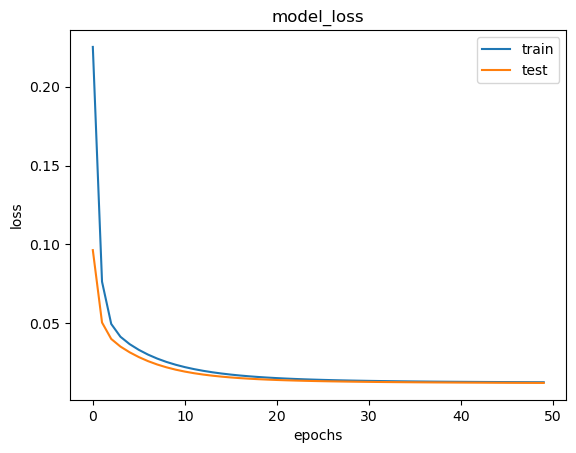

In [33]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model_loss')
plt.ylabel('loss')
plt.xlabel('epochs')
plt.legend(['train', 'test'], loc= 'upper right')
plt.show()

In [34]:
from sklearn.metrics import r2_score
y_pred = scl_y.inverse_transform(model.predict(X_test_scaled))
r2_score(y_test, y_pred)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


0.678236722946167

In [ ]:
model.summary() # which is → X_test_scaled.shape[1] + 1(bias)

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 1)              │            14 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16 (68.00 B)

 Trainable params: 14 (56.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

14

#### Multi-Layer Perceptron

In [63]:
initializer = tf.keras.initializers.GlorotUniform(seed= 25)
tf.random.set_seed(seed=25)
model = tf.keras.Sequential([tf.keras.Input(shape=(X_train_scaled.shape[1],)),
                            tf.keras.layers.Dense(10,activation='relu', kernel_initializer=initializer),
                            tf.keras.layers.Dense(5, kernel_initializer=initializer),
                            tf.keras.layers.Dense(1, kernel_initializer=initializer)]) # first parameter → no. layers
model.compile(optimizer= tf.keras.optimizers.SGD(learning_rate= 0.1),
              loss='mean_squared_error')
history = model.fit(X_train_scaled, y_train_scaled, validation_data=(X_test_scaled, y_test_scaled), epochs= 50)

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.1653 - val_loss: 0.0440
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0459 - val_loss: 0.0302
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0336 - val_loss: 0.0242
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0287 - val_loss: 0.0212
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0258 - val_loss: 0.0212
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0243 - val_loss: 0.0197
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0229 - val_loss: 0.0174
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0214 - val_loss: 0.0188
Epoch 9/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0208 - val_loss: 0.0182
Epoch 10/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0200 - val_loss: 0.0178
Epoch 11/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0192 - val_loss: 0.0173
Epoch 12/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0186 - val_l

In [64]:
from sklearn.metrics import r2_score
y_pred = scl_y.inverse_transform(model.predict(X_test_scaled))
r2_score(y_test, y_pred)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


0.7672715187072754

In [54]:
model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 10)             │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203 (816.00 B)

 Trainable params: 201 (804.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

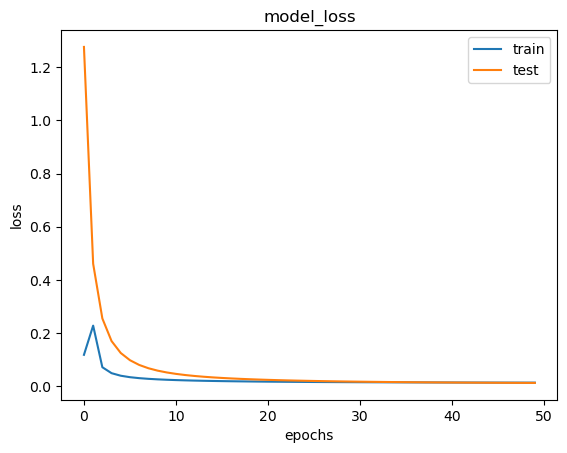

In [44]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model_loss')
plt.ylabel('loss')
plt.xlabel('epochs')
plt.legend(['train', 'test'], loc= 'upper right')
plt.show()

In [66]:
initializer = tf.keras.initializers.GlorotUniform(seed= 25)
tf.random.set_seed(seed=25)
model = tf.keras.Sequential([tf.keras.Input(shape=(X_train_scaled.shape[1],)),
                            tf.keras.layers.Dense(10,activation='relu', kernel_initializer=initializer),
                            tf.keras.layers.Dense(5, kernel_initializer=initializer),
                            tf.keras.layers.Dense(1, kernel_initializer=initializer)]) # first parameter → no. layers
model.compile(optimizer= tf.keras.optimizers.Adam(learning_rate=0.1),
              loss='mean_squared_error')
history = model.fit(X_train_scaled, y_train_scaled, validation_data=(X_test_scaled, y_test_scaled), epochs= 50)

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.5269 - val_loss: 0.0652
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0707 - val_loss: 0.0448
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0504 - val_loss: 0.0399
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0448 - val_loss: 0.0400
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0466 - val_loss: 0.0390
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0450 - val_loss: 0.0376
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0445 - val_loss: 0.0384
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0453 - val_loss: 0.0389
Epoch 9/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0455 - val_loss: 0.0389
Epoch 10/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0454 - val_loss: 0.0389
Epoch 11/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0454 - val_loss: 0.0390
Epoch 12/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0455 - val_